In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utility import *
from tools import *
from maps import *
from identify import *
from scipy.stats import linregress
from scipy.ndimage import maximum_filter, binary_dilation
from scipy.spatial.distance import cdist
from scipy.signal import detrend
from scipy.stats import pearsonr
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [ ]:
# Load the Data's directory.
datadir_1 = 'C:/Users/Kevin/Desktop/Analysis/04_01_02.zda'
datadir_2 = 'C:/Users/Kevin/Desktop/Analysis/04_01_04.zda'

# Load the Tool Packages.
dataLoader_1 = DataLoader(datadir_1)
dataLoader_2 = DataLoader(datadir_2)
tools = Tools()
maps = Maps()
identify = Identify()

In [3]:
# Parameters setting up.
timeline = np.linspace(0, 499.5, 1000)
basePt = 194
skipPt = 46
startPt = 200
numPt = 40
stimulus = 200

In [4]:
# Data Preprocessing for data_1.
Data_1 = dataLoader_1.get_data()
Data_1 = tools.Polynomial(startPt=basePt, numPt=skipPt, Data=Data_1)
Rli_1 = dataLoader_1.get_rli()
Data_1 = tools.Rli_Division(Rli=Rli_1, Data=Data_1)
Data_1 = tools.T_filter(Data=Data_1)
Data_1 = tools.S_filter(sigma=1, Data=Data_1)
Data_ave_1 = np.mean(Data_1, axis=0)

# SNR Map for data_1. (Without Normalization)
snr_map_1 = maps.SNR_Map(startPt=startPt, numPt=numPt, Data=Data_1)

# Maximum Amplitude Map for data_1. (Without Normalization)
max_map_1 = maps.Max_Amp_Map(startPt=startPt, numPt=numPt, Data=Data_1)

# Rli Map for data_1.
rli_high = np.array(Rli_1['rli_high'])
rli_low = np.array(Rli_1['rli_low'])

rli_1 = ((rli_high - rli_low) / 3276.8)
bad = np.where(rli_1==0)
for coor in bad:
    rli_1[coor] = 0
rli_1 = rli_1.reshape(80, 80)

In [5]:
# Data Preprocessing for data_2.
Data_2 = dataLoader_2.get_data()
Data_2 = tools.Polynomial(startPt=basePt, numPt=skipPt, Data=Data_2)
Rli_2 = dataLoader_2.get_rli()
Data_2 = tools.Rli_Division(Rli=Rli_2, Data=Data_2)
Data_2 = tools.T_filter(Data=Data_2)
Data_2 = tools.S_filter(sigma=1, Data=Data_2)
Data_ave_2 = np.mean(Data_2, axis=0)

# SNR Map for data_2. (Without Normalization)
snr_map_2 = maps.SNR_Map(startPt=startPt, numPt=numPt, Data=Data_2)

# Maximum Amplitude Map for data_2. (Without Normalization)
max_map_2 = maps.Max_Amp_Map(startPt=startPt, numPt=numPt, Data=Data_2)

# Rli Map for data_2.
rli_high = np.array(Rli_2['rli_high'])
rli_low = np.array(Rli_2['rli_low'])

rli_2 = ((rli_high - rli_low) / 3276.8)
bad = np.where(rli_2==0)
for coor in bad:
    rli_2[coor] = 0
rli_2 = rli_2.reshape(80, 80)

In [6]:
# Stimulation Site.
# evoke = np.array([41, 34])
evoke = np.array([60, 34])
# evoke = np.array([56, 16])

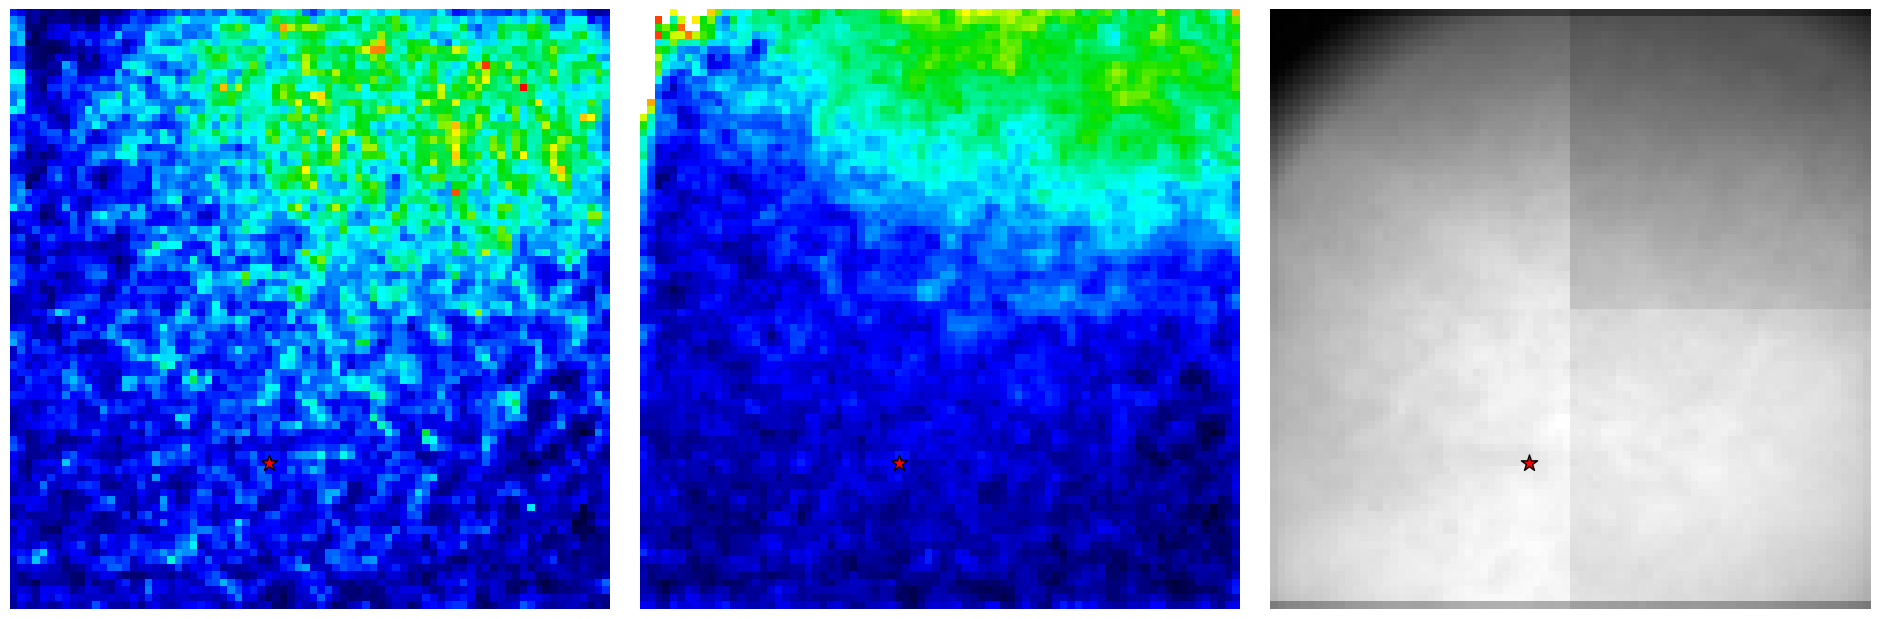

In [7]:
# Plotting Heat Maps and Rli Map for Data #1.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 8))

# SNR Map for Data #1.
ax1.imshow(snr_map_1 / np.max(snr_map_1), vmin=0, vmax=1, cmap=maps.colorbar())
# ax1.set_title('SNR Map for Data #1 (Without Blocker)')
ax1.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=150, marker='*')
ax1.axis('off')

# Heat Map for Data #1.
ax2.imshow(max_map_1, vmin=0, vmax=0.012, cmap=maps.colorbar())
# ax2.set_title('Maximum_Amp Map for Data #1 (Without Blocker)')
ax2.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=150, marker='*')
ax2.axis('off')

# Rli Map for Data #1.
ax3.imshow(rli_1, cmap='gray')
# ax3.set_title('Rli Map for Data #1 (Without Blocker)')
ax3.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=150, marker='*')
ax3.axis('off')

fig.subplots_adjust(wspace=0.05)
plt.show()

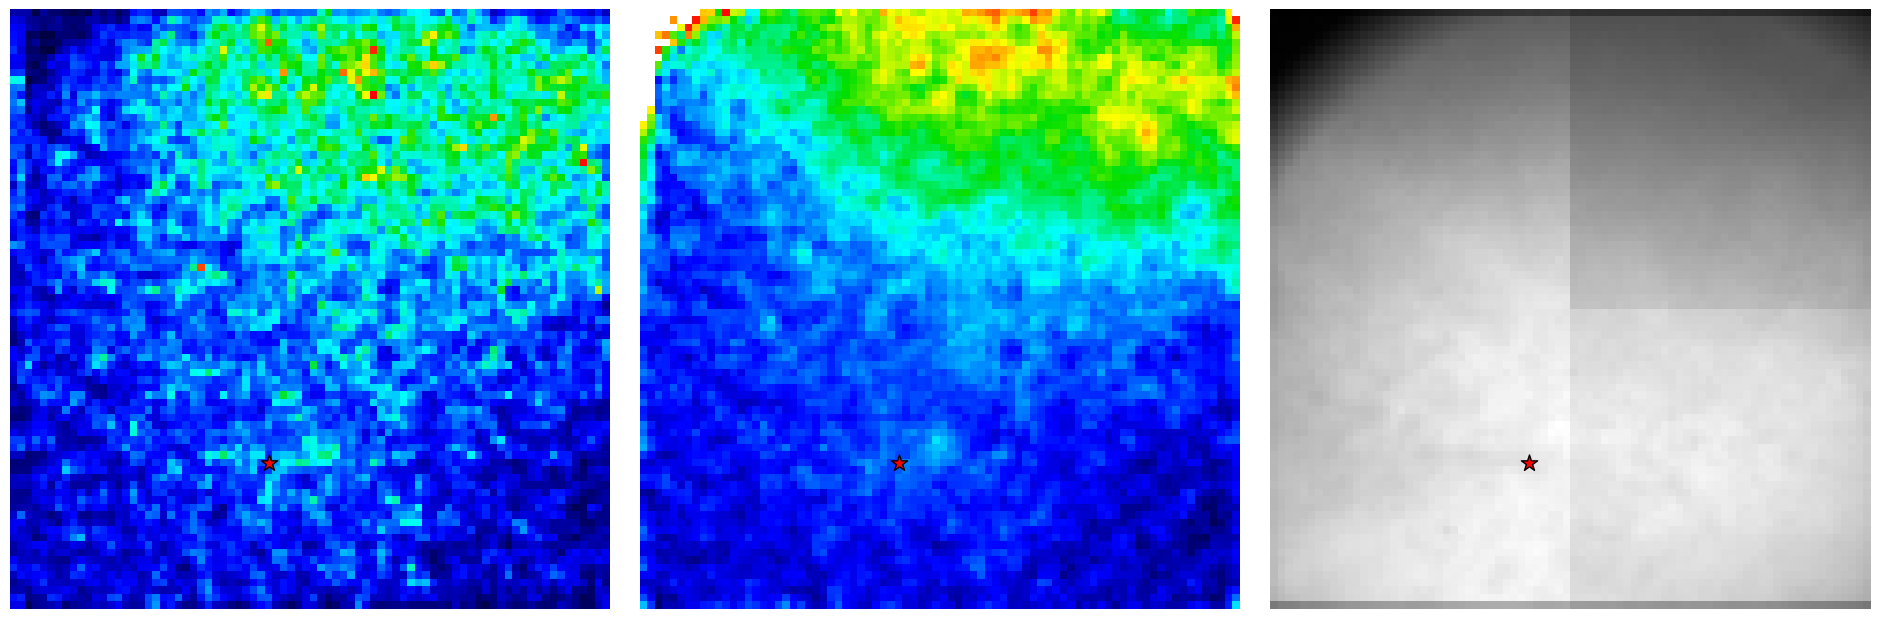

In [8]:
# Plotting Heat Maps and Rli Map for Data #2.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 8))

# SNR Map for Data #2.
ax1.imshow(snr_map_2 / np.max(snr_map_2), vmin=0, vmax=1, cmap=maps.colorbar())
# ax1.set_title('SNR Map for Data #2 (Add Blocker)')
ax1.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=150, marker='*')
ax1.axis('off')

# Heat Map for Data #2.
ax2.imshow(max_map_2, vmin=0, vmax=0.012, cmap=maps.colorbar())
# ax2.set_title('Maximum_Amp Map for Data #2 (Add Blocker)')
ax2.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=150, marker='*')
ax2.axis('off')

# Rli Map for Data #2.
ax3.imshow(rli_2, cmap='gray')
# ax3.set_title('Rli Map for Data #2 (Add Blocker)')
ax3.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=150, marker='*')
ax3.axis('off')

fig.subplots_adjust(wspace=0.05)
plt.show()

In [9]:
# Single Cell Identification for Data #1.
candidates_1 = identify.candidates(Data_ave=Data_ave_1, cutoff=99, startPt=startPt, numPt=numPt)
candidates_1 = identify.select_non_overlap(candidates=candidates_1, snr_map=snr_map_1)
candidates_1 = sorted(candidates_1, key=lambda x: (x[0], x[1]))

In [10]:
# Single Cell Identification for Data #2.
candidates_2 = identify.candidates(Data_ave=Data_ave_2, cutoff=99, startPt=startPt, numPt=numPt)
candidates_2 = identify.select_non_overlap(candidates=candidates_2, snr_map=snr_map_2)
candidates_2 = sorted(candidates_2, key=lambda x: (x[0], x[1]))

In [11]:
# Parameters setting.
color = 'red'
linewidth = 1.5
index_1 = [(x[0], x[1]) for x in candidates_1]
index_2 = [(x[0], x[1]) for x in candidates_2]

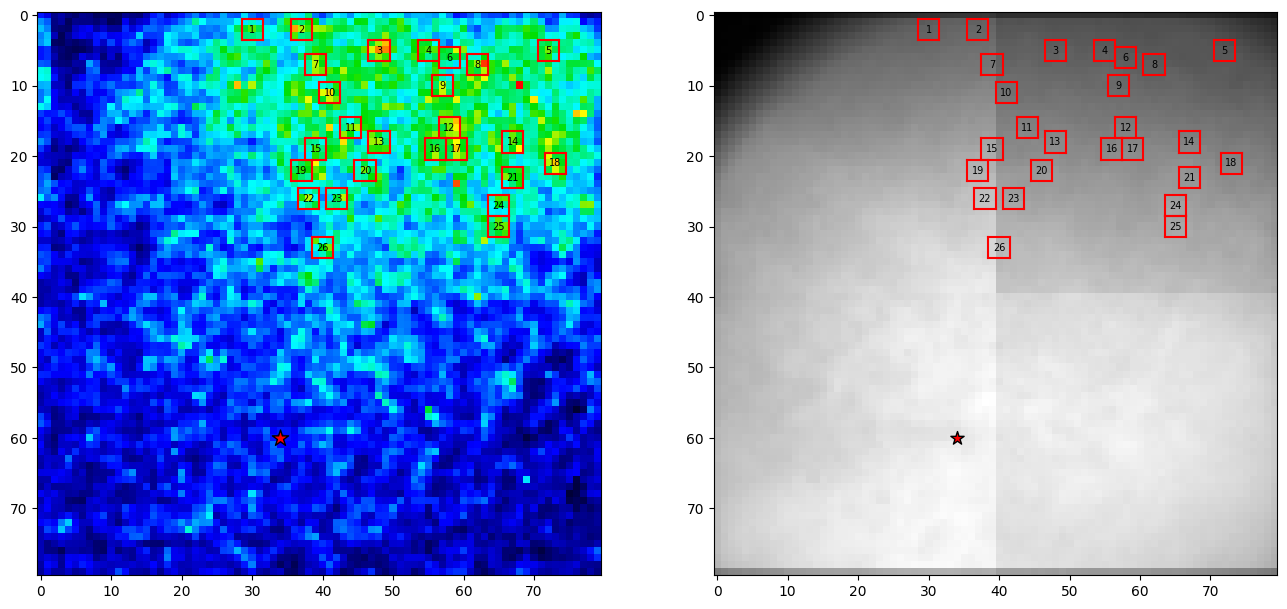

In [12]:
# Visualization of the identified cells on the SNR Maps and Rli Maps for Data #1.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# SNR Map for Data #1 with identified cells.
ax1 = plt.subplot(1, 2, 1)
ax1.imshow(snr_map_1 / np.max(snr_map_1), vmin=0, vmax=1, cmap=maps.colorbar())
ax1.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=150, marker='*')

for i, coor in enumerate(index_1):

    #  Coordinates for columns and rows.   
    r = coor[1]
    c = coor[0]

    # Pixel boundaries.
    top    = r - 1.5
    bottom = r + 1.5
    left   = c - 1.5
    right  = c + 1.5

    # Draw square contour.
    ax1.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax1.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    ax1.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')

# Rli Map for Data #1 with identified cells.
ax2 = plt.subplot(1, 2, 2)  
ax2.imshow(rli_1, cmap='gray')
ax2.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')

for i, coor in enumerate(index_1):

    #  Coordinates for columns and rows.   
    c = coor[0]
    r = coor[1]

    # Pixel boundaries.
    left   = c - 1.5
    right  = c + 1.5
    top    = r - 1.5
    bottom = r + 1.5

    # Draw square contour.
    ax2.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax2.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    ax2.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')
    
plt.show()

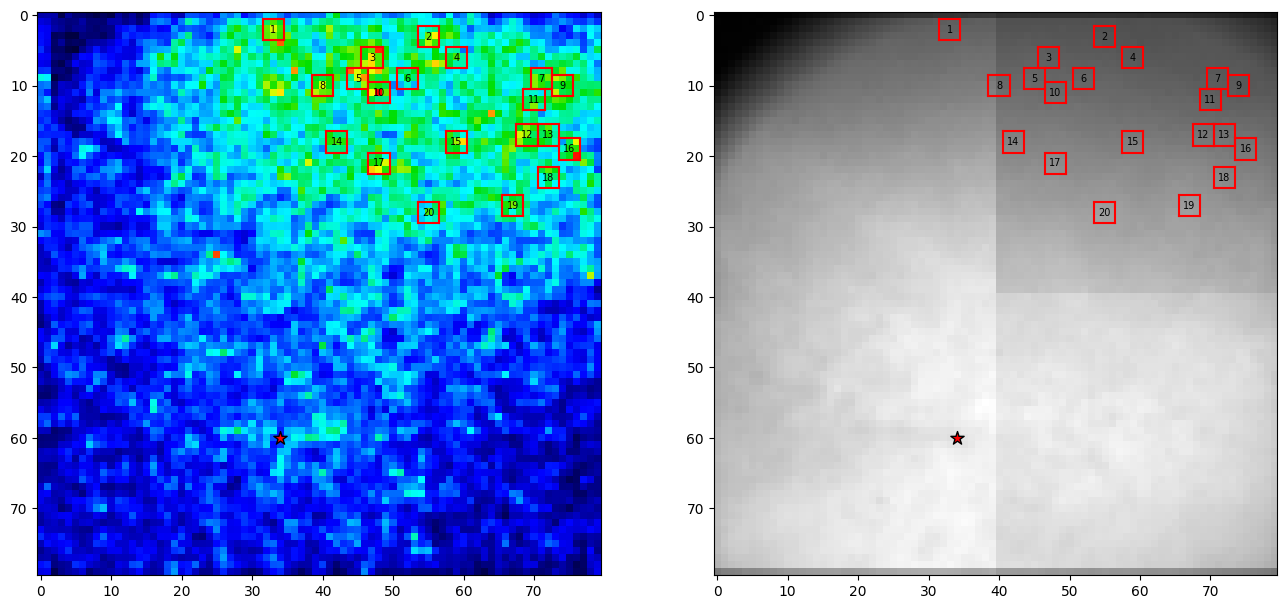

In [13]:
# Visualization of the identified cells on the SNR Maps and Rli Maps for Data #2.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# SNR Map for Data #2 with identified cells.
ax1 = plt.subplot(1, 2, 1)
ax1.imshow(snr_map_2 / np.max(snr_map_2), vmin=0, vmax=1, cmap=maps.colorbar())
ax1.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')

for i, coor in enumerate(index_2):

    #  Coordinates for columns and rows.   
    c = coor[0]
    r = coor[1]

    # Pixel boundaries.
    left   = c - 1.5
    right  = c + 1.5
    top    = r - 1.5
    bottom = r + 1.5

    # Draw square contour.
    ax1.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax1.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    ax1.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')
    
# Rli Map for Data #2 with identified cells.
ax2 = plt.subplot(1, 2, 2)  
ax2.imshow(rli_2, cmap='gray')
ax2.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')

for i, coor in enumerate(index_2):

    #  Coordinates for columns and rows.   
    c = coor[0]
    r = coor[1]

    # Pixel boundaries.
    left   = c - 1.5
    right  = c + 1.5
    top    = r - 1.5
    bottom = r + 1.5

    # Draw square contour.
    ax2.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax2.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    ax2.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')

plt.show()

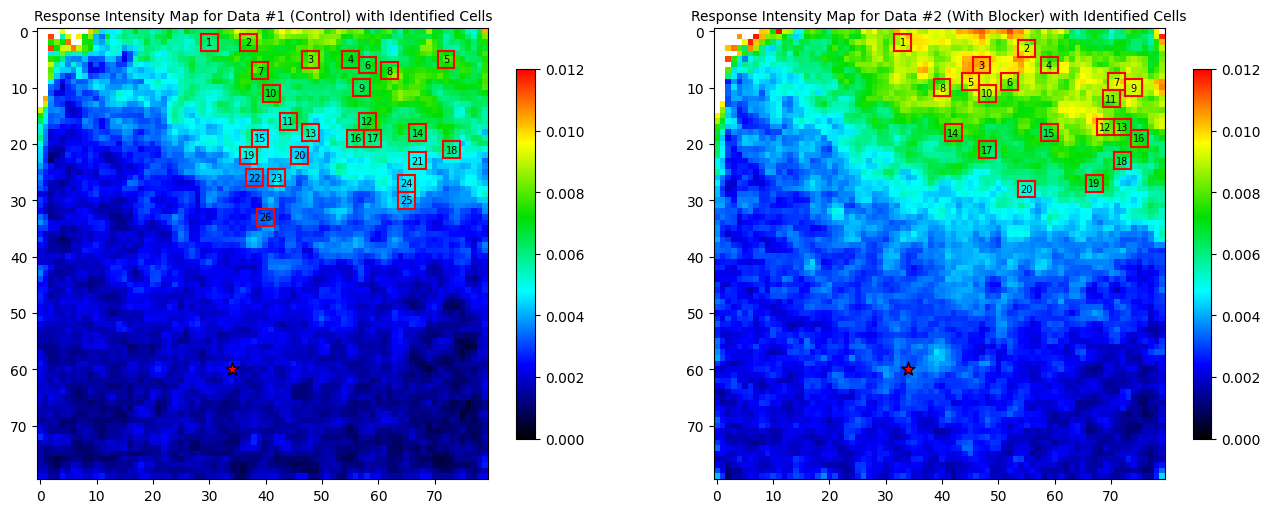

In [14]:
# Visualization of the identified cells on the Response Intensity Maps for Data #1 and Data #2.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,8))

# Response Intensity Map for Data #1 with identified cells.
im1 = ax1.imshow(max_map_1, vmin=0, vmax=0.012, cmap=maps.colorbar())
ax1.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')
ax1.set_title('Response Intensity Map for Data #1 (Control) with Identified Cells', fontsize=10)

for i, coor in enumerate(index_1):

    #  Coordinates for columns and rows.   
    c = coor[0]
    r = coor[1]

    # Pixel boundaries.
    left   = c - 1.5
    right  = c + 1.5
    top    = r - 1.5
    bottom = r + 1.5

    # Draw square contour.
    ax1.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax1.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    ax1.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')

cbar1 = fig.colorbar(im1, ax=ax1, shrink=0.6)
    
# Response Intensity Map for Data #2 with identified cells.
im2 = ax2.imshow(max_map_2, vmin=0, vmax=0.012, cmap=maps.colorbar())
ax2.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')
ax2.set_title('Response Intensity Map for Data #2 (With Blocker) with Identified Cells', fontsize=10)

for i, coor in enumerate(index_2):

    #  Coordinates for columns and rows.   
    c = coor[0]
    r = coor[1]

    # Pixel boundaries.
    left   = c - 1.5
    right  = c + 1.5
    top    = r - 1.5
    bottom = r + 1.5

    # Draw square contour.
    ax2.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax2.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    ax2.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')

cbar2 = fig.colorbar(im2, ax=ax2, shrink=0.6)
    
plt.show()

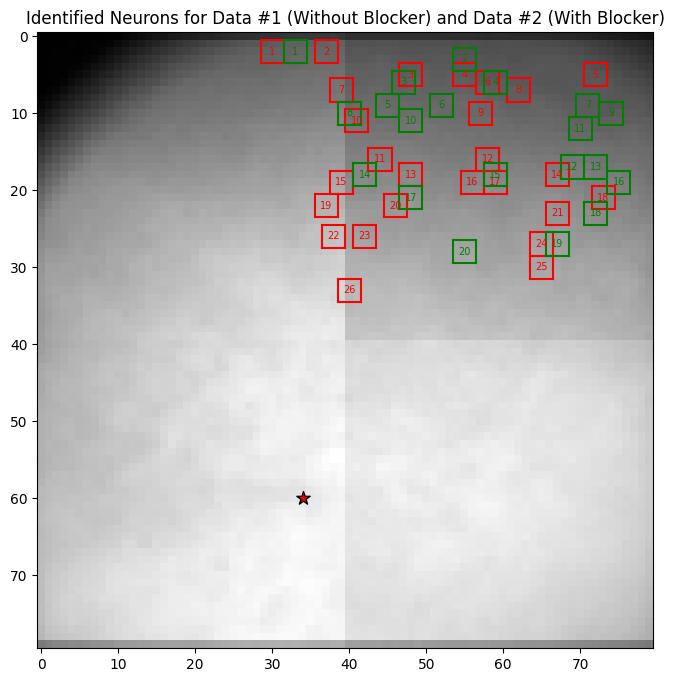

In [15]:
plt.figure(figsize=(8, 8))
plt.imshow(rli_1, cmap='gray')
plt.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker="*")
plt.title('Identified Neurons for Data #1 (Without Blocker) and Data #2 (With Blocker)')

for i, coor in enumerate(index_1):

    #  Coordinates for columns and rows.   
    r = coor[1]
    c = coor[0]

    # Pixel boundaries.
    top    = r - 1.5
    bottom = r + 1.5
    left   = c - 1.5
    right  = c + 1.5

    # Draw square contour.
    plt.plot([top, top], [left, right], color=color, linewidth=linewidth)
    plt.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    plt.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    plt.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    plt.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='red')

for i, coor in enumerate(index_2):

    #  Coordinates for columns and rows.   
    c = coor[0]
    r = coor[1]

    # Pixel boundaries.
    left   = c - 1.5
    right  = c + 1.5
    top    = r - 1.5
    bottom = r + 1.5

    # Draw square contour.
    plt.plot([top, top], [left, right], color='green', linewidth=linewidth)
    plt.plot([bottom, bottom], [left, right], color='green', linewidth=linewidth)
    plt.plot([top, bottom], [left, left], color='green', linewidth=linewidth)
    plt.plot([top, bottom], [right, right], color='green', linewidth=linewidth)

    # Label index.
    plt.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='green')

plt.show()

In [16]:
n_cells = len(candidates_1)

cell_trace_1 = np.empty((n_cells, 1000))
cell_amp_1 = np.empty(n_cells)
cell_dist_1 = np.empty(n_cells)

for i, candidate in enumerate(candidates_1):

    coords = np.asarray(candidate[3])

    trace = Data_ave_1[coords[:, 0], coords[:, 1], :].mean(axis=0)

    cell_trace_1[i] = trace

    cell_amp_1[i] = np.max(trace[startPt:startPt + numPt])

    cell_dist_1[i] = (np.hypot(candidate[0] - evoke[0], candidate[1] - evoke[1]) * 6)
    
# Pearson correlation
r, p = pearsonr(cell_dist_1, cell_amp_1)

# Linear regression
result = linregress(cell_dist_1, cell_amp_1)

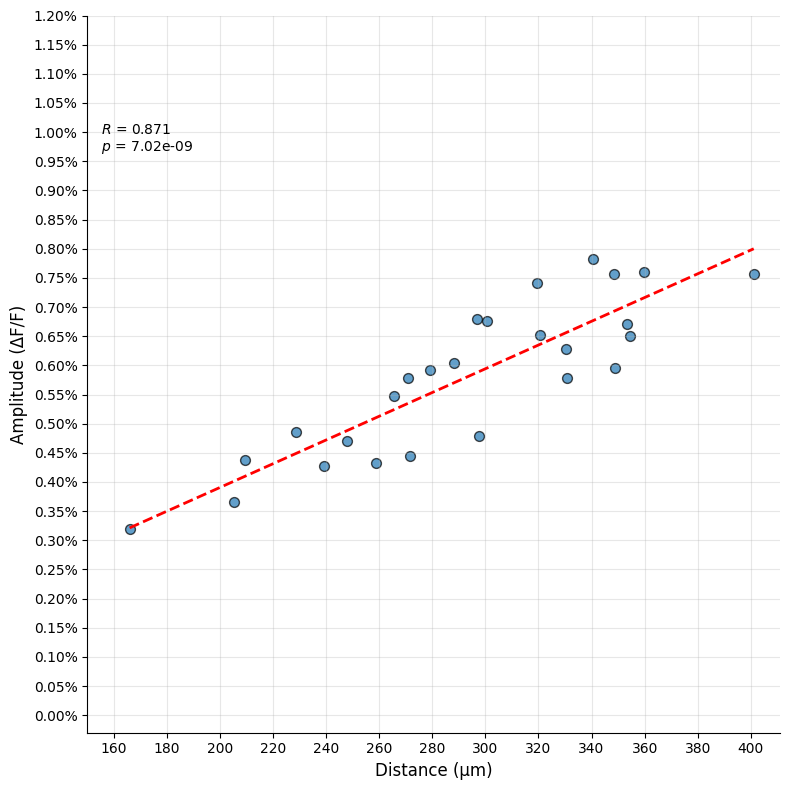

In [17]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(cell_dist_1, cell_amp_1, color='tab:blue', edgecolors='black', s=50, alpha=0.7)

# Remove top/right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Labels
ax.set_xlabel('Distance (μm)', fontsize=12)
ax.set_ylabel('Amplitude (ΔF/F)', fontsize=12)

# Linear regression line
x = np.linspace(cell_dist_1.min(), cell_dist_1.max(), 200)
y = result.slope * x + result.intercept

ax.plot(x, y, color='red', linewidth=2, linestyle='--')

ax.text(0.02, 0.85, f'$R$ = {result.rvalue:.3f}\n$p$ = {result.pvalue:.2e}', transform=ax.transAxes, ha='left', va='top', fontsize=10)

# Axis
ax.set_ylim(-0.0003, 0.012)
ax.set_xlim(150, 411)

# Tick labels
yticks = np.arange(0, 0.0121, 0.0005)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.2%}' for y in yticks], fontsize=10)

xticks = np.arange(160, 401, 20)
ax.set_xticks(xticks)
ax.set_xticklabels([f'{y}' for y in xticks], fontsize=10)

ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [18]:
n_cells = len(candidates_2)

cell_trace_2 = np.empty((n_cells, 1000))
cell_amp_2 = np.empty(n_cells)
cell_dist_2 = np.empty(n_cells)

for i, candidate in enumerate(candidates_2):

    coords = np.asarray(candidate[3])

    trace = Data_ave_2[coords[:, 0], coords[:, 1], :].mean(axis=0)

    cell_trace_2[i] = trace

    cell_amp_2[i] = np.max(trace[startPt:startPt + numPt])

    cell_dist_2[i] = (np.hypot(candidate[0] - evoke[0], candidate[1] - evoke[1]) * 6)
    
# Pearson correlation
r, p = pearsonr(cell_dist_2, cell_amp_2)

# Linear regression
result = linregress(cell_dist_2, cell_amp_2)

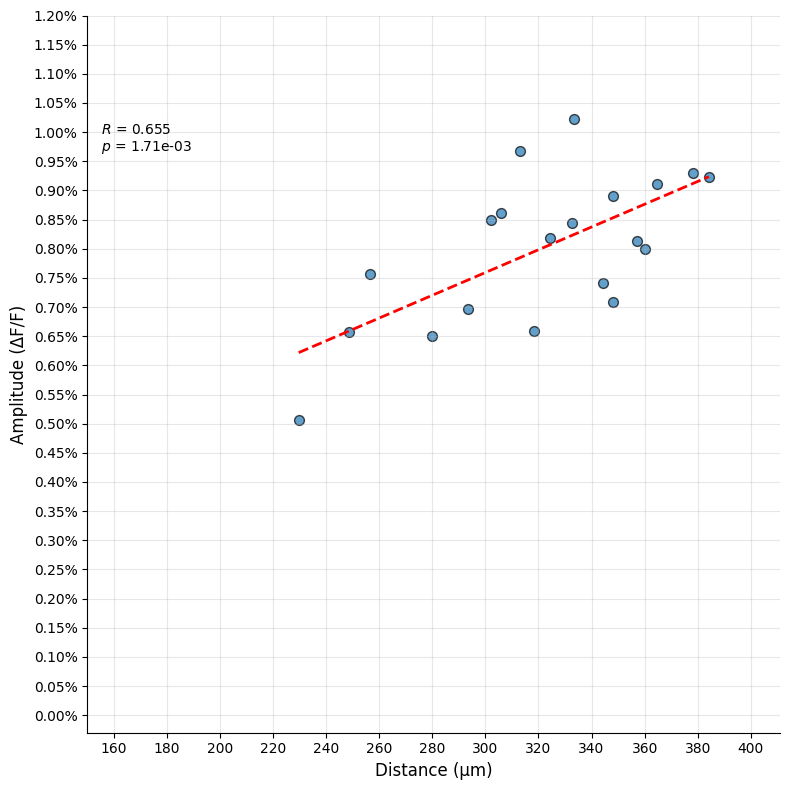

In [19]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(cell_dist_2, cell_amp_2, color='tab:blue', edgecolors='black', s=50, alpha=0.7)

# Remove top/right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Labels
ax.set_xlabel('Distance (μm)', fontsize=12)
ax.set_ylabel('Amplitude (ΔF/F)', fontsize=12)

# Linear regression line
x = np.linspace(cell_dist_2.min(), cell_dist_2.max(), 200)
y = result.slope * x + result.intercept

ax.plot(x, y, color='red', linewidth=2, linestyle='--')

ax.text(0.02, 0.85, f'$R$ = {result.rvalue:.3f}\n$p$ = {result.pvalue:.2e}', transform=ax.transAxes, ha='left', va='top', fontsize=10)

# Axis
ax.set_ylim(-0.0003, 0.012)
ax.set_xlim(150, 411)

# Tick labels
yticks = np.arange(0, 0.0121, 0.0005)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.2%}' for y in yticks], fontsize=10)

xticks = np.arange(160, 401, 20)
ax.set_xticks(xticks)
ax.set_xticklabels([f'{y}' for y in xticks], fontsize=10)

ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [20]:
# Parameters setting. (For Data #1)
num = len(index_1)
candi = candidates_1
trial = Data_1.shape[0]

latency_1 = np.zeros((num, trial))
trace_1 = np.zeros((num, trial, len(timeline)))

for i in range(num):
    for j in range(trial):
        data_tem = []
        for coor in candi[i][3]:
            data_tem.append(Data_1[j, coor[0], coor[1], :])
        data_tem = np.array(data_tem)
        Trace = np.mean(data_tem, axis=0)
        trace_1[i][j] = Trace
        latency_1[i][j] = maps.Half_Amp_Latency_3(Trace=Trace, startPt=startPt, numPt=numPt)

In [21]:
# Parameters setting. (For Data #2)
num = len(index_1)
candi = candidates_1
trial = Data_2.shape[0]

latency_2 = np.zeros((num, trial))
trace_2 = np.zeros((num, trial, len(timeline)))

for i in range(num):
    for j in range(trial):
        data_tem = []
        for coor in candi[i][3]:
            data_tem.append(Data_2[j, coor[0], coor[1], :])
        data_tem = np.array(data_tem)
        Trace = np.mean(data_tem, axis=0)
        trace_2[i][j] = Trace
        latency_2[i][j] = maps.Half_Amp_Latency_3(Trace=Trace, startPt=startPt, numPt=numPt)

In [22]:
locate_1 = []
Amp_1 = []
locate_2 = []
Amp_2 = []

# For Data #1.
for i, coor in enumerate(index_1):
    value = np.sqrt((coor[0] - evoke[0])**2 + (coor[1] - evoke[1])**2) * 6
    if value <= 50:
        continue
    else:
        locate_1.append(value)
        Amp_1.append(np.max(Data_ave_1[coor[0], coor[1], startPt:(startPt+numPt)]))

# For Data #2.
for i, coor in enumerate(index_2):
    value = np.sqrt((coor[0] - evoke[0])**2 + (coor[1] - evoke[1])**2) * 6
    if value <= 50:
        continue
    else:
        locate_2.append(value)
        Amp_2.append(np.max(Data_ave_2[coor[0], coor[1], startPt:(startPt+numPt)]))

locate_1 = np.array(locate_1)
Amp_1 = np.array(Amp_1)

locate_2 = np.array(locate_2)
Amp_2 = np.array(Amp_2)

<>:37: SyntaxWarning: invalid escape sequence '\D'
<>:37: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Kevin\AppData\Local\Temp\ipykernel_11380\1146242886.py:37: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel('$\Delta$F/F', fontsize=14)


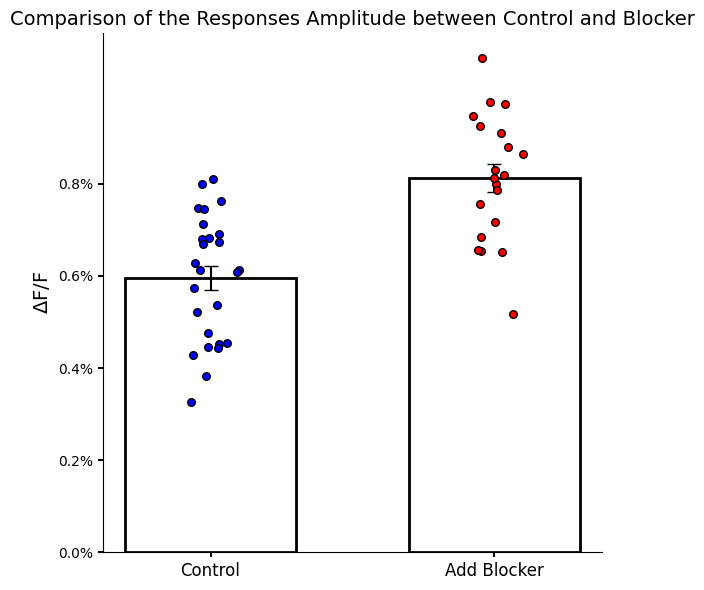

In [23]:
groups = [Amp_1, Amp_2]
labels = ['Control', 'Add Blocker']

# Calculate statistics
means = [np.mean(g) for g in groups]
sems = [np.std(g, ddof=1) / np.sqrt(len(g)) for g in groups]

# Plot
fig, ax = plt.subplots(figsize=(6,6))

x = np.arange(len(groups))
y = np.arange(0, 0.01, 0.002)

# Bar
ax.bar(x, means, yerr=sems, capsize=5, width=0.6, facecolor='white', edgecolor='black', linewidth=2, zorder=1)

# Scatter points
for i, g in enumerate(groups):

    # Add a small horizontal jitter
    jitter = np.random.normal(0, 0.05, size=len(g))

    if i == 0:
        color = 'blue'
    else:
        color = 'red'
    
    ax.scatter(np.full(len(g), x[i]) + jitter, g, facecolor=color, edgecolor='black', s=30, zorder=3, linewidth=1)

# Formatting
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)

ax.set_yticks(y)
ax.set_yticklabels(['{}%'.format(d*100) for d in y])

ax.set_ylabel('$\Delta$F/F', fontsize=14)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(direction='out', width=1.5)

plt.title('Comparison of the Responses Amplitude between Control and Blocker', fontsize=14)
plt.tight_layout()
plt.show()

Neuron 1 and Neuron 6 are correlated with a positive slope, and the P-Value is: 0.009477 , distance is: 169.7056274847714 um.
Neuron 1 and Neuron 19 are correlated with a positive slope, and the P-Value is: 0.047722 , distance is: 127.13772060250255 um.
Neuron 2 and Neuron 11 are correlated with a positive slope, and the P-Value is: 0.040979 , distance is: 93.91485505499116 um.
Neuron 2 and Neuron 20 are correlated with a positive slope, and the P-Value is: 0.004932 , distance is: 131.59027319676784 um.
Neuron 3 and Neuron 24 are correlated with a positive slope, and the P-Value is: 0.036519 , distance is: 166.81726529349413 um.
Neuron 5 and Neuron 24 are correlated with a positive slope, and the P-Value is: 0.006509 , distance is: 138.52075656738236 um.
Neuron 6 and Neuron 19 are correlated with a positive slope, and the P-Value is: 0.043241 , distance is: 158.40454538932903 um.
Neuron 7 and Neuron 15 are correlated with a positive slope, and the P-Value is: 0.037401 , distance is: 72

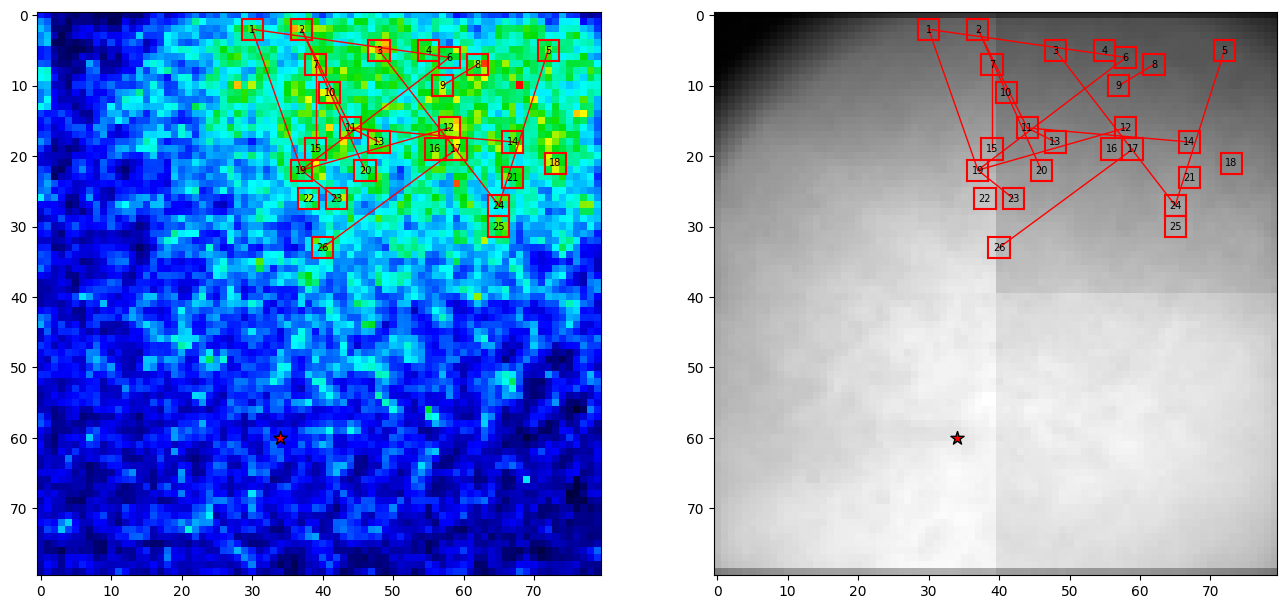

14 pairs are correlated.
Totally 325 pairs.


In [24]:
# Parameters setting. (For Data #1)
length_1 = len(candidates_1)
index = index_1
trial = Data_1.shape[0]
count = 0

plt.subplots(1, 2, figsize=(16,8))
ax1 = plt.subplot(1, 2, 1)
ax2 = plt.subplot(1, 2, 2)
ax1.imshow(snr_map_1 / np.max(snr_map_1), vmin=0, vmax=1, cmap=maps.colorbar())
ax1.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')
ax2.imshow(rli_1, cmap='gray')
ax2.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')

for i, coor in enumerate(index):

    #  Coordinates for columns and rows.   
    c = coor[0]
    r = coor[1]

    # Pixel boundaries.
    left   = c - 1.5
    right  = c + 1.5
    top    = r - 1.5
    bottom = r + 1.5

    # Draw square contour.
    ax1.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax1.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    ax2.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax2.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    ax1.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')
    ax2.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')

for i in range(length_1-1):
    for j in range(i+1, length_1):
        
        dist = np.sqrt((index[i][0] - index[j][0])**2 + (index[i][1] - index[j][1])**2) * 6
        Slope, _, _, pValue, _ = linregress(latency_1[i], latency_1[j])
        if pValue <=0.05 and Slope > 0:
            count = count + 1
            print('Neuron', i+1, 'and Neuron', j+1, 'are correlated with a positive slope, and the P-Value is:', 
                  np.round(pValue, 6), ', distance is:', dist, 'um.')
            loc_1 = index[i]
            loc_2 = index[j]
            ax1.plot([loc_1[1], loc_2[1]], [loc_1[0], loc_2[0]], color='red', linewidth=1)
            ax2.plot([loc_1[1], loc_2[1]], [loc_1[0], loc_2[0]], color='red', linewidth=1)

plt.show()

print(count, 'pairs are correlated.')
print('Totally', int(length_1*(length_1-1)/2), 'pairs.')

Neuron 2 and Neuron 15 are correlated with a positive slope, and the P-Value is: 0.018951 , distance is: 93.14504817756014 um.
Neuron 3 and Neuron 9 are correlated with a positive slope, and the P-Value is: 0.008161 , distance is: 163.76812876747417 um.
Neuron 3 and Neuron 10 are correlated with a positive slope, and the P-Value is: 0.017334 , distance is: 30.594117081556707 um.
Neuron 5 and Neuron 7 are correlated with a positive slope, and the P-Value is: 0.011338 , distance is: 156.0 um.
Neuron 5 and Neuron 18 are correlated with a positive slope, and the P-Value is: 0.010856 , distance is: 182.4828759089466 um.
Neuron 6 and Neuron 10 are correlated with a positive slope, and the P-Value is: 0.017312 , distance is: 26.832815729997478 um.
Neuron 6 and Neuron 17 are correlated with a positive slope, and the P-Value is: 0.010431 , distance is: 75.8946638440411 um.
Neuron 6 and Neuron 18 are correlated with a positive slope, and the P-Value is: 0.015139 , distance is: 146.4786673888044 

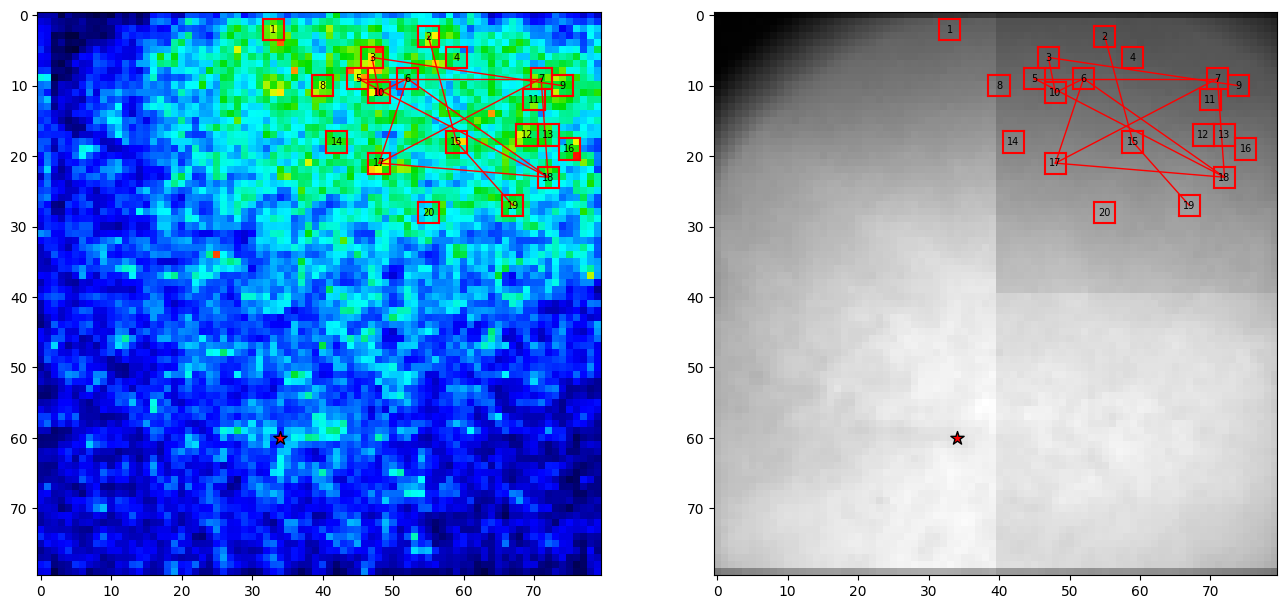

12 pairs are correlated.
Totally 190 pairs.


In [25]:
# Parameters setting. (For Data #2)
length_2 = len(candidates_2)
index = index_2
trial = Data_2.shape[0]

count = 0

plt.subplots(1, 2, figsize=(16,8))
ax1 = plt.subplot(1, 2, 1)
ax2 = plt.subplot(1, 2, 2)
ax1.imshow(snr_map_2 / np.max(snr_map_2), vmin=0, vmax=1, cmap=maps.colorbar())
ax1.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')
ax2.imshow(rli_2, cmap='gray')
ax2.scatter(evoke[1], evoke[0], color='red', edgecolors='black', s=100, marker='*')

for i, coor in enumerate(index):

    #  Coordinates for columns and rows.   
    c = coor[0]
    r = coor[1]

    # Pixel boundaries.
    left   = c - 1.5
    right  = c + 1.5
    top    = r - 1.5
    bottom = r + 1.5

    # Draw square contour.
    ax1.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax1.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax1.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    ax2.plot([top, top], [left, right], color=color, linewidth=linewidth)
    ax2.plot([bottom, bottom], [left, right], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [left, left], color=color, linewidth=linewidth)
    ax2.plot([top, bottom], [right, right], color=color, linewidth=linewidth)

    # Label index.
    ax1.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')
    ax2.annotate(str(i+1), xy=(r, c), ha='center', va='center', fontsize=7, color='black')

for i in range(length_2-1):
    for j in range(i+1, length_2):
        
        dist = np.sqrt((index[i][0] - index[j][0])**2 + (index[i][1] - index[j][1])**2) * 6
        Slope, _, _, pValue, _ = linregress(latency_2[i], latency_2[j])
        if pValue <=0.05 and Slope > 0:
            count = count + 1
            print('Neuron', i+1, 'and Neuron', j+1, 'are correlated with a positive slope, and the P-Value is:', 
                  np.round(pValue, 6), ', distance is:', dist, 'um.')
            loc_1 = index[i]
            loc_2 = index[j]
            ax1.plot([loc_1[1], loc_2[1]], [loc_1[0], loc_2[0]], color='red', linewidth=1)
            ax2.plot([loc_1[1], loc_2[1]], [loc_1[0], loc_2[0]], color='red', linewidth=1)

plt.show()

print(count, 'pairs are correlated.')
print('Totally', int(length_2*(length_2-1)/2), 'pairs.')

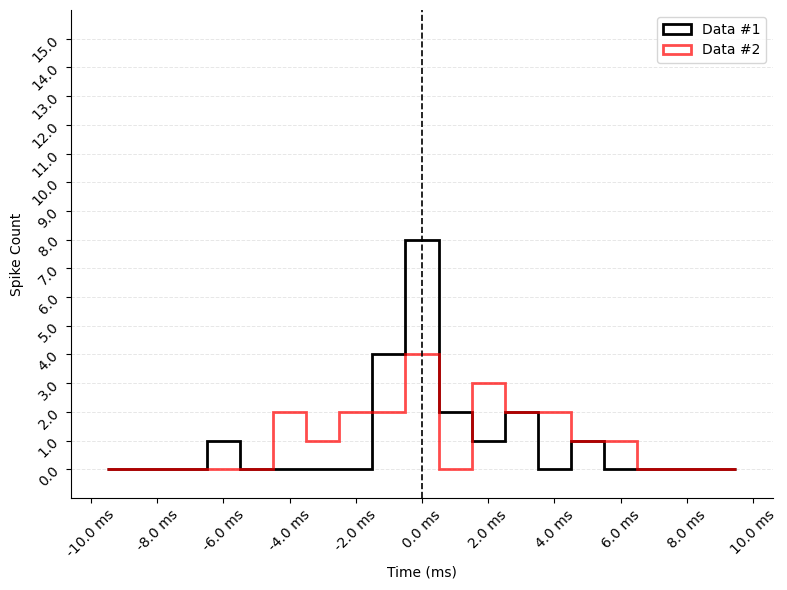

In [38]:
# DATA
cell_1_1 = 11
cell_1_2 = 13
cell_2_1 = 15
cell_2_2 = 19

cell_count_1 = []
cell_count_2 = []

# Half Amplitude Latency.
'''
for i in range(Data_1.shape[0]):
    cell_count_1.append(latency_1[cell_1_1-1][i] - latency_1[cell_1_2-1][i])
    cell_count_2.append(latency_2[cell_2_1-1][i] - latency_2[cell_2_2-1][i])
'''

# Maximum Amplitude Latency.

for i in range(Data_1.shape[0]):
    peak_idx1 = np.argmax(trace_1[cell_1_1-1][i][startPt:startPt+numPt]) + startPt
    peak_idx1 = peak_idx1 / 2
    peak_idx2 = np.argmax(trace_1[cell_1_2-1][i][startPt:startPt+numPt]) + startPt
    peak_idx2 = peak_idx2 / 2
    cell_count_1.append(peak_idx1 - peak_idx2)
    peak_idx1 = np.argmax(trace_2[cell_2_1-1][i][startPt:startPt+numPt]) + startPt
    peak_idx1 = peak_idx1 / 2
    peak_idx2 = np.argmax(trace_2[cell_2_2-1][i][startPt:startPt+numPt]) + startPt
    peak_idx2 = peak_idx2 / 2
    cell_count_2.append(peak_idx1 - peak_idx2)


cell_count_1 = np.array(cell_count_1)
cell_count_2 = np.array(cell_count_2)

# Histogram
fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(cell_count_1, range=(-9.5, 9.5), bins=19, histtype='step', edgecolor='black', linewidth=2, label='Data #1')
ax.hist(cell_count_2, range=(-9.5, 9.5), bins=19, histtype='step', edgecolor='red', alpha=0.7, linewidth=2, label='Data #2')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xticks(np.arange(-10, 10.5, 2))
ax.set_xticklabels([f'{x} ms' for x in np.arange(-10, 10.5, 2)], rotation=45)
ax.set_yticks(np.arange(0, 15.6, 1))
ax.set_yticklabels([f'{y}' for y in np.arange(0, 15.6, 1)], rotation=45)
ax.set_xlim(-10.6, 10.6)
ax.set_ylim(-1, 16)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Spike Count')
ax.axvline(0, color='black', linewidth=1.2, linestyle='--')
ax.grid(axis='y', linestyle='--', linewidth=0.7, alpha=0.3)
ax.legend(loc='upper right', fontsize=10)

fig.tight_layout()
plt.show()

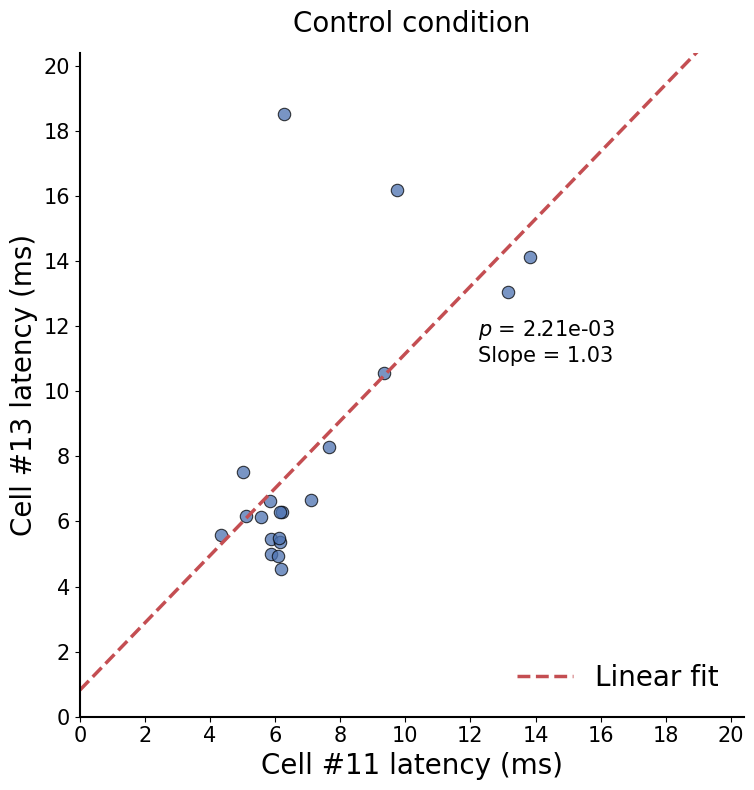

In [37]:
# Cells' Number
cell_1 = 11
cell_2 = 13

# regression
x_data = latency_1[cell_1-1] - 100
y_data = latency_1[cell_2-1] - 100

slope, intercept, rvalue, pvalue, stderr = linregress(x_data, y_data)

x_fit = np.linspace(0, 24, 200)
y_fit = slope * x_fit + intercept

fig, ax = plt.subplots(figsize=(8,8), dpi=100)

# SCATTER

ax.scatter(x_data, y_data, s=80, color='#4C72B0', alpha=0.75, edgecolor='black', linewidth=0.8)

# LINEAR FIT

ax.plot(x_fit, y_fit, color='#C44E52', linewidth=2.5, linestyle = '--', label='Linear fit')

# AXIS

ax.set_xlim(0, 20.4)
ax.set_ylim(0, 20.4)

ax.set_xticks(np.arange(0, 20.4, 2.0))
ax.set_yticks(np.arange(0, 20.4, 2.0))

ax.tick_params(labelsize=15)

ax.set_xlabel(f'Cell #{cell_1} latency (ms)', fontsize=20)

ax.set_ylabel(f'Cell #{cell_2} latency (ms)', fontsize=20)

# equal aspect
ax.set_aspect('equal')

# STATS BOX

stats_text = (f'$p$ = {pvalue:.2e}\n'f'Slope = {slope:.2f}')

ax.text(0.6, 0.6, stats_text, transform=ax.transAxes, fontsize=15, va='top', bbox=dict(facecolor='white', alpha=0.85, edgecolor='none'))

# STYLE

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

ax.legend(frameon=False, fontsize=20, loc='lower right')

ax.set_title(f'Control condition', fontsize=20, pad=15)

plt.tight_layout()
plt.show()

c:\Users\Kevin\Desktop\Python\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\Kevin\Desktop\Python\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


IndexError: list index out of range

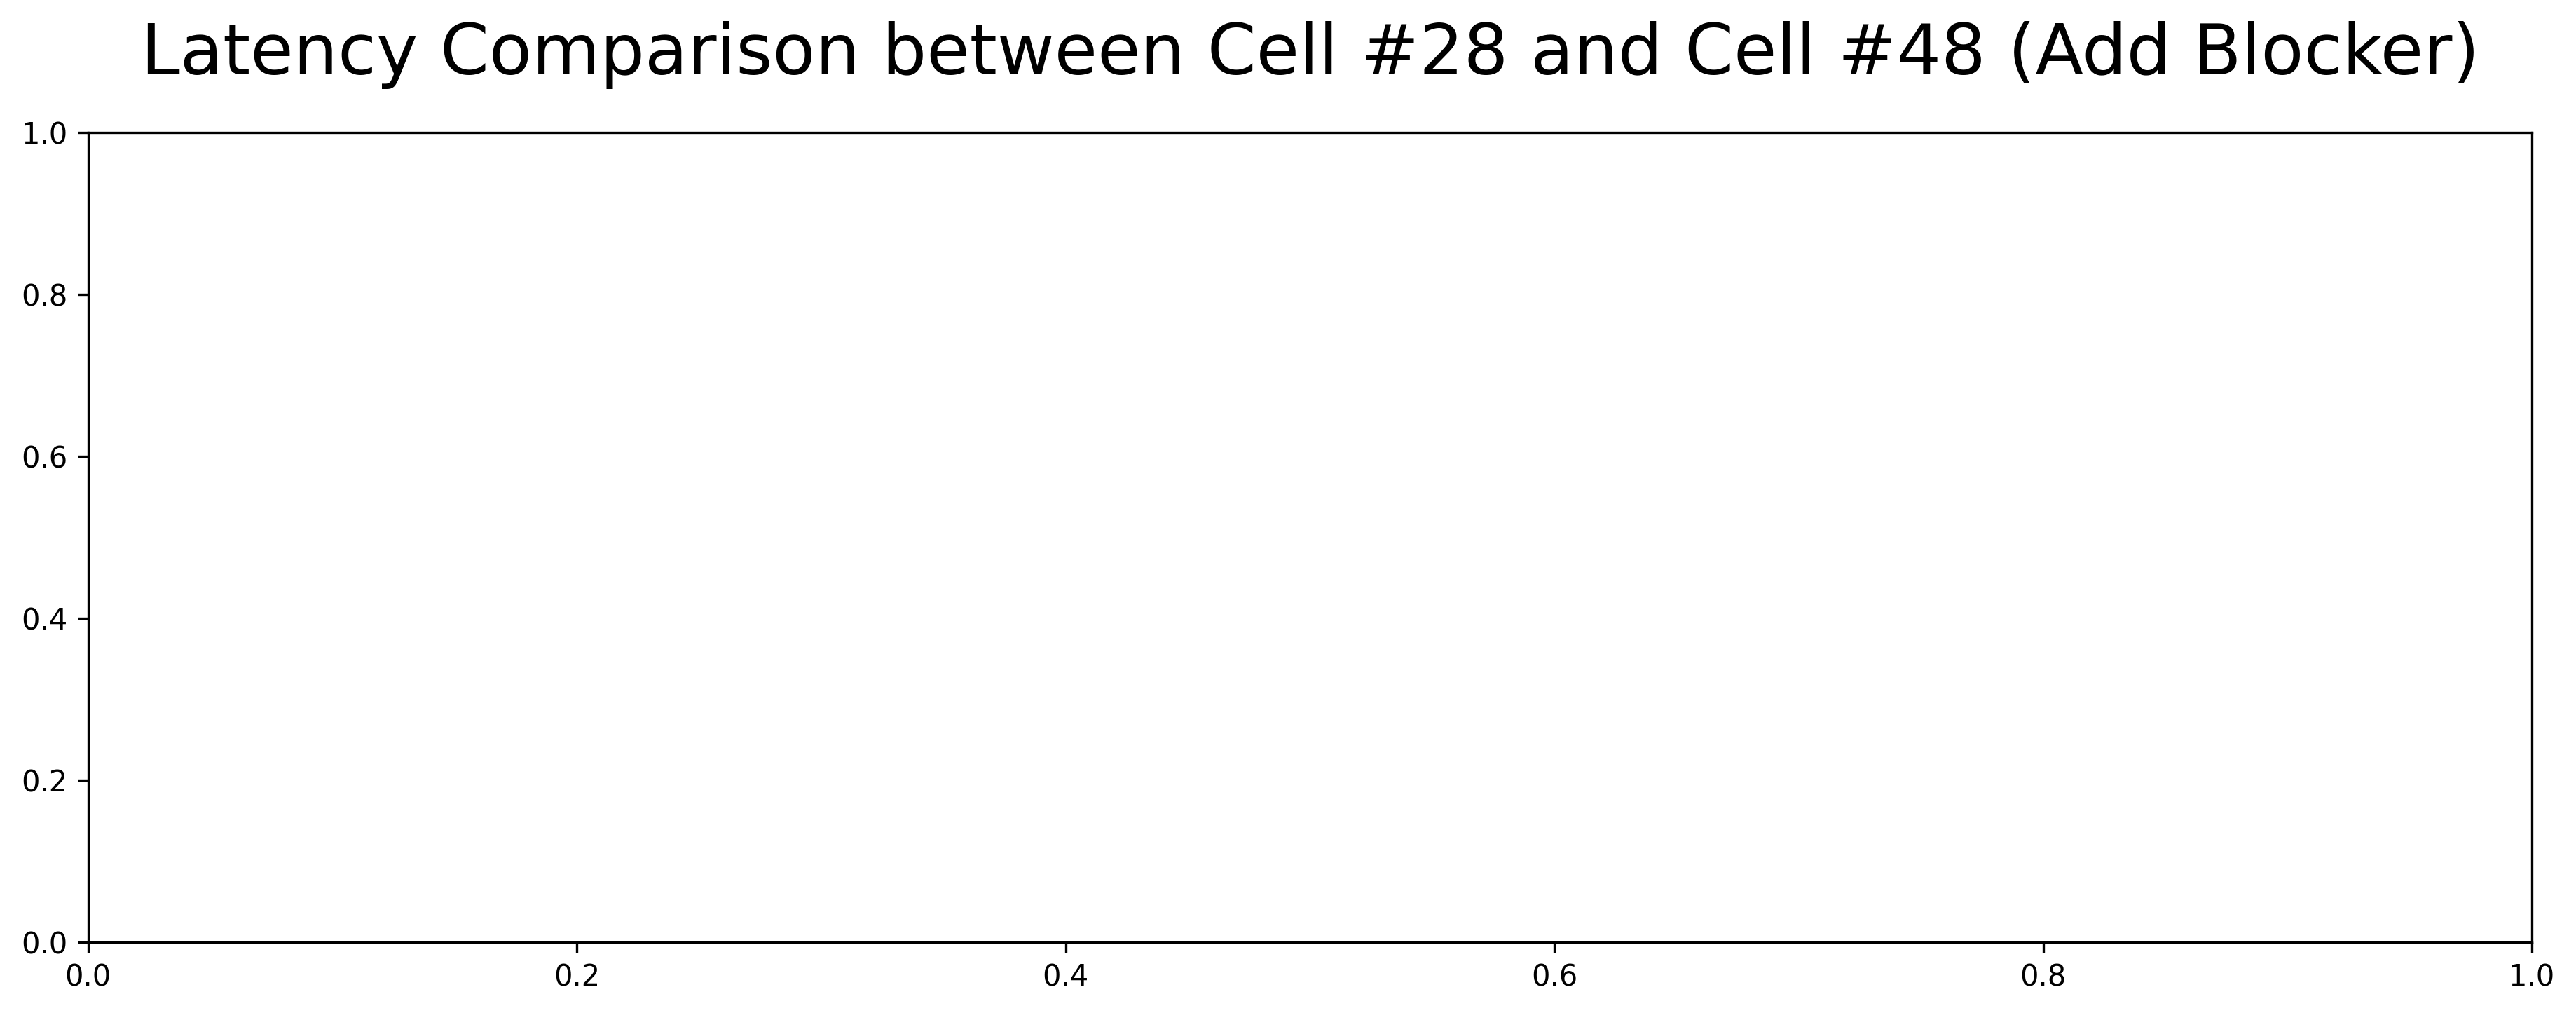

In [28]:
fig, ax = plt.subplots(figsize=(15,5), dpi=300)
ax.set_title('Latency Comparison between Cell #28 and Cell #48 (Add Blocker)', fontsize=24, pad=20)

# DATA

trace1 = np.mean([])
trace1 = Data_ave_2[index_2[28-1][0], index_2[28-1][1], :]
trace2 = Data_ave_2[index_2[48-1][0], index_2[48-1][1], :]

peak_idx1 = np.argmax(trace1)
peak_idx2 = np.argmax(trace2)

peak_t1 = timeline[peak_idx1]
peak_t2 = timeline[peak_idx2]

latency_diff = abs(peak_t2 - peak_t1)

# TRACES (main signal)
ax.plot(timeline, trace1, color='#4C72B0', linewidth=2.5, label='Cell #28')

ax.plot(timeline, trace2, color='#C44E52', linewidth=2.5, label='Cell #48')

# STIMULATION
stim_t = 100

ax.axvline(stim_t, color='black', linestyle='--', linewidth=2, alpha=0.7)

ax.text(stim_t - 5, max(trace1.max(), trace2.max()) * 0.85, 'Stim', fontsize=16)

# PEAK markers (subtle)
ax.axvline(peak_t1, color='#4C72B0', linestyle=':', linewidth=2)
ax.axvline(peak_t2, color='#C44E52', linestyle=':', linewidth=2)

# LATENCY BRACKET (main conclusion)
y_bar = max(trace1.max(), trace2.max()) * 1.05

ax.plot([peak_t1, peak_t2], [y_bar, y_bar], color='black', linewidth=2)

ax.plot([peak_t1, peak_t1], [y_bar*0.98, y_bar*1.02], color='black', linewidth=2)
ax.plot([peak_t2, peak_t2], [y_bar*0.98, y_bar*1.02], color='black', linewidth=2)

ax.text((peak_t1 + peak_t2)/2 + 10, y_bar * 1.03, f'Δt = {latency_diff:.1f} ms', ha='center', fontsize=16, fontweight='bold')

# SCALE BAR (NEW)

x0 = 65
y0 = min(trace1.max(), trace2.max()) * 0.8

dx = 10        # 10 ms
dy = 0.002     # ΔF/F scale

# horizontal (time)
ax.plot([x0, x0+dx], [y0, y0], color='black', linewidth=3)

# vertical (amplitude)
ax.plot([x0, x0], [y0, y0+dy], color='black', linewidth=3)

# labels
ax.text(x0 + dx/2, y0 - 0.0008, '10 ms', ha='center', fontsize=14)

ax.text(x0 - 3, y0 + dy/2, '0.2% ΔF/F', va='center', rotation=90, fontsize=14)

# AXIS STYLE
ax.set_xlim(50, 150)
ax.set_ylim(min(trace1.min(), trace2.min())*1.2, max(trace1.max(), trace2.max())*1.2)

ax.set_xlabel('Time (ms)', fontsize=20)
ax.set_ylabel('ΔF/F', fontsize=20)

ax.tick_params(labelsize=15)
ax.set_xticks(np.arange(60, 151, 20))

# SPINES (clean look)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

# LEGEND (clean)

ax.legend(frameon=False, fontsize=18, loc='upper right')

plt.tight_layout()
plt.show()